# Practical Assignment 2: Problem Solving Through Search

* Name: Yashraj Ghule
* Div: E
* Batch: E1
* Roll no: 316
* PRN: 202401040319

**GITHUB:** https://github.com/Yashraj221B/AIML_TH_LAB/tree/main/C.A/Practical-02-Problem-Solving-Through-Search

## Problem Statement

To implement and compare search algorithms from each family on a suitable problem, using solution quality, number of nodes explored and run time.

| Search family | Algorithms | Benchmark problem |
|---|---|---|
| Uninformed | BFS, DFS, UCS | Weighted grid maze |
| Informed | Greedy Best-First, A* | Same maze, Manhattan heuristic |
| Local search | Hill Climbing, Simulated Annealing | 8-Queens |
| Constraint satisfaction | Backtracking, MRV + Forward Checking | Australia map colouring and random maps |

## 1. Import libraries and setup

In [1]:
import heapq
import math
import random
import time
from collections import deque

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_SEED = 42
random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Problem 1: weighted grid maze

The maze is a 20 x 20 grid. About 25% of the cells are walls and about 20% are "rough" cells that cost 5 to enter, all other cells cost 1. We move up, down, left or right and want to go from the top-left corner to the bottom-right corner. Because of the rough cells, the path with the fewest steps is not always the cheapest path, so BFS and UCS should give different answers.

In [2]:
SIZE = 20
START = (0, 0)
GOAL = (SIZE - 1, SIZE - 1)

def make_maze(seed):
    rng = random.Random(seed)
    cost = {}
    for r in range(SIZE):
        for c in range(SIZE):
            x = rng.random()
            if (r, c) in (START, GOAL):
                cost[(r, c)] = 1
            elif x < 0.25:
                cost[(r, c)] = None          # wall
            elif x < 0.45:
                cost[(r, c)] = 5             # rough cell
            else:
                cost[(r, c)] = 1
    return cost

def neighbors(maze, cell):
    r, c = cell
    result = []
    for dr, dc in [(-1, 0), (1, 0), (0, -1), (0, 1)]:
        nxt = (r + dr, c + dc)
        if nxt in maze and maze[nxt] is not None:
            result.append(nxt)
    return result

def step_cost(maze, cell):
    return maze[cell]

def heuristic(cell, goal=GOAL):
    # Manhattan distance, every move costs at least 1 so it never overestimates
    return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])

def reconstruct_path(parent, goal):
    if goal not in parent:
        return None
    path = []
    current = goal
    while current is not None:
        path.append(current)
        current = parent[current]
    return path[::-1]

def path_cost(maze, path):
    return sum(maze[cell] for cell in path[1:]) if path else None

# pick the first seed that has a path from start to goal
seed = 0
while True:
    maze = make_maze(seed)
    seen, queue = {START}, deque([START])
    while queue:
        node = queue.popleft()
        for nb in neighbors(maze, node):
            if nb not in seen:
                seen.add(nb)
                queue.append(nb)
    if GOAL in seen:
        break
    seed += 1

walls = sum(1 for v in maze.values() if v is None)
rough = sum(1 for v in maze.values() if v == 5)
print("Maze seed:", seed)
print("Walls:", walls, "| Rough cells:", rough)

Maze seed: 0
Walls: 90 | Rough cells: 82


## 3. Evaluation metrics

For every algorithm we record:

* **Path cost:** sum of the cell costs along the returned path.
* **Path length:** number of moves.
* **Expanded nodes:** number of nodes taken out of the frontier and processed.
* **Time:** run time in milliseconds for this run.

## 4. Uninformed search

* **BFS** expands level by level, so it gives the path with the fewest moves, but it ignores cell costs.
* **DFS** goes as deep as it can before backtracking, so it is not optimal.
* **UCS** always expands the node with the lowest cost so far, so it is optimal for non-negative costs.

In [3]:
def breadth_first_search(maze, start, goal):
    frontier = deque([start])
    parent = {start: None}
    expanded = 0
    while frontier:
        node = frontier.popleft()
        expanded += 1
        if node == goal:
            break
        for nb in neighbors(maze, node):
            if nb not in parent:
                parent[nb] = node
                frontier.append(nb)
    path = reconstruct_path(parent, goal)
    return {"algorithm": "BFS", "path": path, "expanded": expanded,
            "path_length": len(path) - 1 if path else None,
            "path_cost": path_cost(maze, path)}

def depth_first_search(maze, start, goal):
    stack = [start]
    parent = {start: None}
    expanded = 0
    while stack:
        node = stack.pop()
        expanded += 1
        if node == goal:
            break
        for nb in neighbors(maze, node):
            if nb not in parent:
                parent[nb] = node
                stack.append(nb)
    path = reconstruct_path(parent, goal)
    return {"algorithm": "DFS", "path": path, "expanded": expanded,
            "path_length": len(path) - 1 if path else None,
            "path_cost": path_cost(maze, path)}

def uniform_cost_search(maze, start, goal):
    frontier = [(0, start)]
    parent = {start: None}
    best_cost = {start: 0}
    expanded = 0
    while frontier:
        cost_so_far, node = heapq.heappop(frontier)
        if cost_so_far != best_cost[node]:
            continue
        expanded += 1
        if node == goal:
            break
        for nb in neighbors(maze, node):
            new_cost = cost_so_far + step_cost(maze, nb)
            if new_cost < best_cost.get(nb, math.inf):
                best_cost[nb] = new_cost
                parent[nb] = node
                heapq.heappush(frontier, (new_cost, nb))
    path = reconstruct_path(parent, goal)
    return {"algorithm": "UCS", "path": path, "expanded": expanded,
            "path_length": len(path) - 1 if path else None,
            "path_cost": path_cost(maze, path)}

def run_and_measure(function, *args):
    t0 = time.perf_counter()
    result = function(*args)
    result["time_ms"] = (time.perf_counter() - t0) * 1000
    return result

uninformed_results = [
    run_and_measure(breadth_first_search, maze, START, GOAL),
    run_and_measure(depth_first_search, maze, START, GOAL),
    run_and_measure(uniform_cost_search, maze, START, GOAL),
]
for r in uninformed_results:
    print(r["algorithm"], "| cost:", r["path_cost"], "| moves:", r["path_length"], "| expanded:", r["expanded"])

BFS | cost: 78 | moves: 38 | expanded: 302
DFS | cost: 200 | moves: 96 | expanded: 106
UCS | cost: 56 | moves: 40 | expanded: 300


## 5. Informed search

* **Greedy Best-First** picks the node with the smallest heuristic value h(n). It is fast but not optimal.
* **A\*** picks the node with the smallest f(n) = g(n) + h(n). The Manhattan distance never overestimates (every move costs at least 1), so A* is optimal.

In [4]:
def greedy_best_first_search(maze, start, goal):
    frontier = [(heuristic(start), start)]
    parent = {start: None}
    visited = set()
    expanded = 0
    while frontier:
        _, node = heapq.heappop(frontier)
        if node in visited:
            continue
        visited.add(node)
        expanded += 1
        if node == goal:
            break
        for nb in neighbors(maze, node):
            if nb not in visited and nb not in parent:
                parent[nb] = node
                heapq.heappush(frontier, (heuristic(nb), nb))
    path = reconstruct_path(parent, goal)
    return {"algorithm": "Greedy", "path": path, "expanded": expanded,
            "path_length": len(path) - 1 if path else None,
            "path_cost": path_cost(maze, path)}

def a_star_search(maze, start, goal):
    frontier = [(heuristic(start), 0, start)]
    parent = {start: None}
    best_g = {start: 0}
    expanded = 0
    while frontier:
        _, g, node = heapq.heappop(frontier)
        if g != best_g[node]:
            continue
        expanded += 1
        if node == goal:
            break
        for nb in neighbors(maze, node):
            new_g = g + step_cost(maze, nb)
            if new_g < best_g.get(nb, math.inf):
                best_g[nb] = new_g
                parent[nb] = node
                heapq.heappush(frontier, (new_g + heuristic(nb), new_g, nb))
    path = reconstruct_path(parent, goal)
    return {"algorithm": "A*", "path": path, "expanded": expanded,
            "path_length": len(path) - 1 if path else None,
            "path_cost": path_cost(maze, path)}

informed_results = [
    run_and_measure(greedy_best_first_search, maze, START, GOAL),
    run_and_measure(a_star_search, maze, START, GOAL),
]
for r in informed_results:
    print(r["algorithm"], "| cost:", r["path_cost"], "| moves:", r["path_length"], "| expanded:", r["expanded"])

Greedy | cost: 80 | moves: 40 | expanded: 42
A* | cost: 56 | moves: 40 | expanded: 290


## 6. Compare the maze results

BFS minimises the number of moves, while UCS and A* minimise the total cost. So a BFS path can have fewer moves but a higher cost.

algorithm  path_length  path_cost  expanded  time_ms
      BFS           38         78       302    0.249
      DFS           96        200       106    0.080
      UCS           40         56       300    0.324
   Greedy           40         80        42    0.096
       A*           40         56       290    0.540


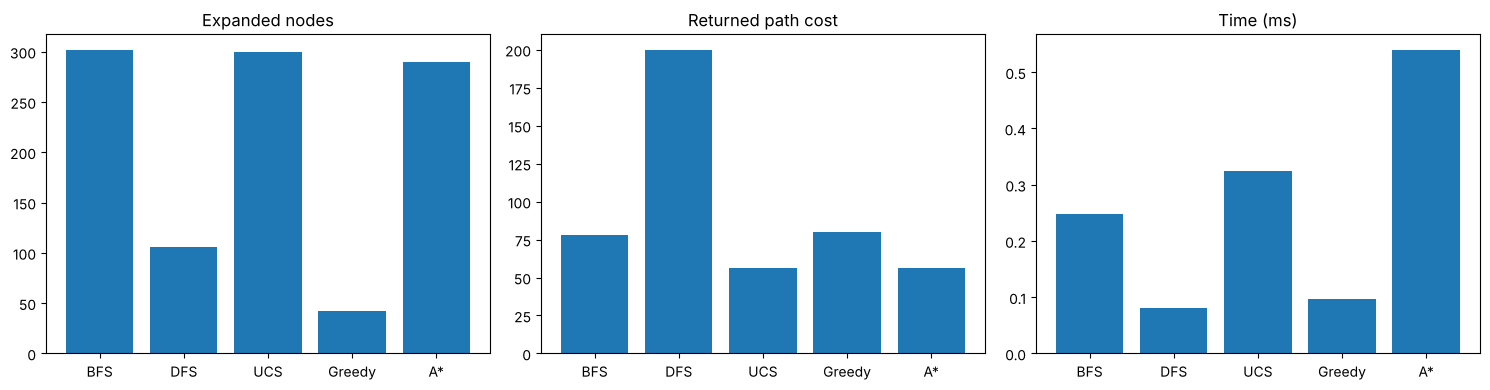

In [5]:
graph_results = uninformed_results + informed_results
search_comparison = pd.DataFrame([
    {key: r[key] for key in ["algorithm", "path_length", "path_cost", "expanded", "time_ms"]}
    for r in graph_results
])
print(search_comparison.round({"time_ms": 3}).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(search_comparison["algorithm"], search_comparison["expanded"])
axes[0].set_title("Expanded nodes")
axes[1].bar(search_comparison["algorithm"], search_comparison["path_cost"])
axes[1].set_title("Returned path cost")
axes[2].bar(search_comparison["algorithm"], search_comparison["time_ms"])
axes[2].set_title("Time (ms)")
plt.tight_layout()
plt.show()

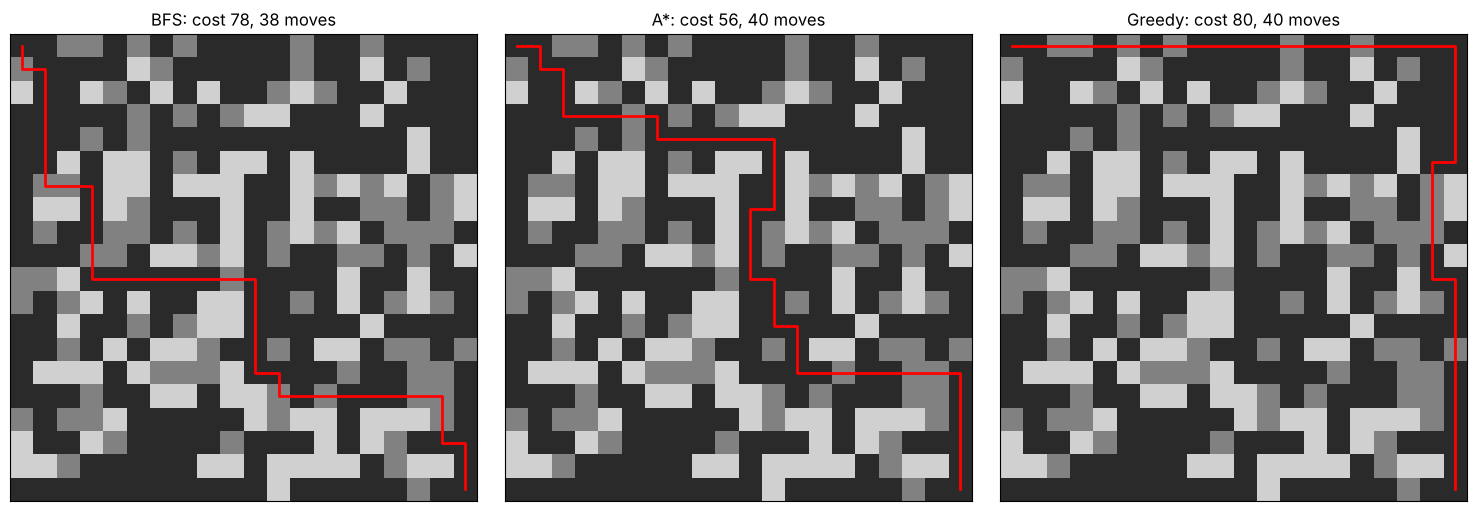

Black = wall, dark grey = rough cell (cost 5), white = normal cell (cost 1)


In [6]:
# draw the maze with the BFS, UCS/A* and Greedy paths
img = np.zeros((SIZE, SIZE))
for (r, c), v in maze.items():
    img[r, c] = 0 if v is None else (1 if v == 5 else 2)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, name in zip(axes, ["BFS", "A*", "Greedy"]):
    res = next(r for r in graph_results if r["algorithm"] == name)
    ax.imshow(img, cmap="Greys", vmin=-1, vmax=2.5)
    ys = [p[0] for p in res["path"]]
    xs = [p[1] for p in res["path"]]
    ax.plot(xs, ys, color="red", linewidth=2)
    ax.set_title(f"{name}: cost {res['path_cost']}, {res['path_length']} moves")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()
print("Black = wall, dark grey = rough cell (cost 5), white = normal cell (cost 1)")

One maze is a small sample, so the same five algorithms are now run on 30 different solvable mazes and averaged.

           average_cost  average_expanded  average_time_ms  optimal_percent
algorithm                                                                  
BFS               80.73            292.33             0.25              0.0
DFS              137.20            133.37             0.12              0.0
UCS               55.53            281.60             0.42            100.0
Greedy            87.87             53.53             0.09              0.0
A*                55.53            205.77             0.38            100.0


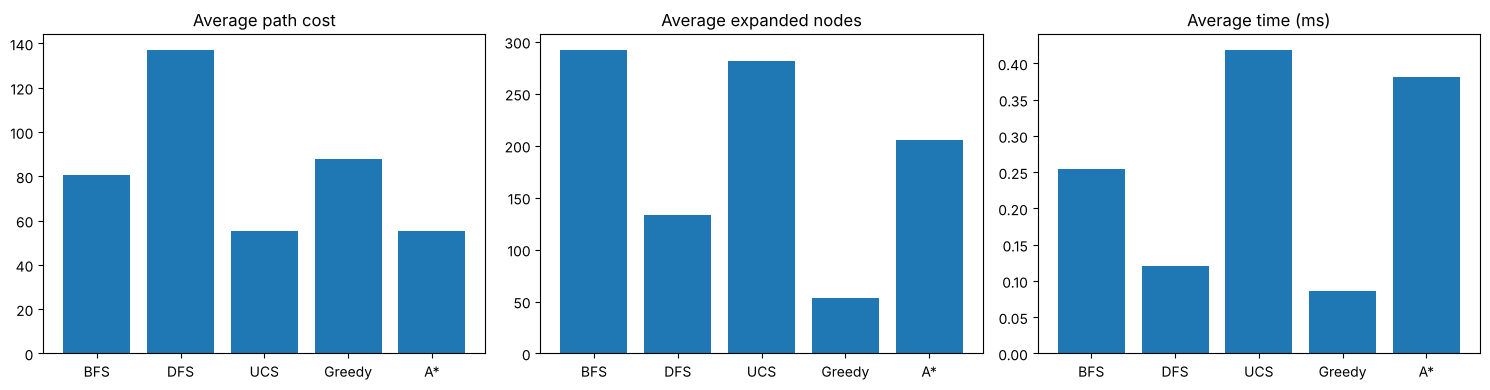

In [7]:
rows = []
found, s = 0, 100
while found < 30:
    m = make_maze(s)
    s += 1
    results = [run_and_measure(f, m, START, GOAL) for f in
               (breadth_first_search, depth_first_search, uniform_cost_search,
                greedy_best_first_search, a_star_search)]
    if results[0]["path"] is None:
        continue
    found += 1
    best = min(r["path_cost"] for r in results)
    for r in results:
        rows.append({"algorithm": r["algorithm"], "path_cost": r["path_cost"],
                     "expanded": r["expanded"], "time_ms": r["time_ms"],
                     "optimal": r["path_cost"] == best})

many = pd.DataFrame(rows)
summary = many.groupby("algorithm").agg(
    average_cost=("path_cost", "mean"),
    average_expanded=("expanded", "mean"),
    average_time_ms=("time_ms", "mean"),
    optimal_percent=("optimal", "mean")).reindex(["BFS", "DFS", "UCS", "Greedy", "A*"])
summary["optimal_percent"] *= 100
print(summary.round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(summary.index, summary["average_cost"]); axes[0].set_title("Average path cost")
axes[1].bar(summary.index, summary["average_expanded"]); axes[1].set_title("Average expanded nodes")
axes[2].bar(summary.index, summary["average_time_ms"]); axes[2].set_title("Average time (ms)")
plt.tight_layout()
plt.show()

## 7. Local search: 8-Queens

One queen is placed in each column of an 8 x 8 board. The state is a list where the index is the column and the value is the row of the queen. The cost is the number of pairs of queens attacking each other, and a solution has cost 0.

* **Hill Climbing:** always moves to the best neighbour and stops when no neighbour is better, so it can get stuck in a local minimum.
* **Simulated Annealing:** sometimes accepts a worse move, with a probability that goes down as the temperature falls, which helps it escape local minima.

In [8]:
def queen_conflicts(state):
    conflicts = 0
    n = len(state)
    for c1 in range(n):
        for c2 in range(c1 + 1, n):
            if state[c1] == state[c2] or abs(state[c1] - state[c2]) == abs(c1 - c2):
                conflicts += 1
    return conflicts

def random_neighbor(state, rng):
    n = len(state)
    neighbor = state.copy()
    col = rng.randrange(n)
    neighbor[col] = rng.choice([row for row in range(n) if row != state[col]])
    return neighbor

def hill_climbing(n=8, seed=0, max_steps=500):
    rng = random.Random(seed)
    state = [rng.randrange(n) for _ in range(n)]
    steps = 0
    for steps in range(1, max_steps + 1):
        current = queen_conflicts(state)
        if current == 0:
            break
        best_score, best_states = current, []
        for col in range(n):
            for row in range(n):
                if row != state[col]:
                    cand = state.copy()
                    cand[col] = row
                    score = queen_conflicts(cand)
                    if score < best_score:
                        best_score, best_states = score, [cand]
                    elif score == best_score and best_states:
                        best_states.append(cand)
        if not best_states:          # no better neighbour, stuck
            break
        state = rng.choice(best_states)
    return {"algorithm": "Hill Climbing", "conflicts": queen_conflicts(state),
            "steps": steps, "solved": queen_conflicts(state) == 0, "state": state}

def simulated_annealing(n=8, seed=0, max_steps=5000, initial_temp=10.0, cooling=0.995):
    rng = random.Random(seed)
    state = [rng.randrange(n) for _ in range(n)]
    score = queen_conflicts(state)
    temperature = initial_temp
    steps = 0
    for steps in range(1, max_steps + 1):
        if score == 0:
            break
        cand = random_neighbor(state, rng)
        cand_score = queen_conflicts(cand)
        delta = cand_score - score
        if delta < 0 or rng.random() < math.exp(-delta / max(temperature, 1e-12)):
            state, score = cand, cand_score
        temperature *= cooling
    return {"algorithm": "Simulated Annealing", "conflicts": queen_conflicts(state),
            "steps": steps, "solved": queen_conflicts(state) == 0, "state": state}

# local search depends on the random start, so run many trials
N_QUEENS = 8
TRIALS = 100
local_rows = []
for trial in range(TRIALS):
    for solver in (hill_climbing, simulated_annealing):
        t0 = time.perf_counter()
        result = solver(n=N_QUEENS, seed=RANDOM_SEED + trial)
        elapsed = (time.perf_counter() - t0) * 1000
        local_rows.append({"algorithm": result["algorithm"], "conflicts": result["conflicts"],
                           "steps": result["steps"], "solved": result["solved"], "time_ms": elapsed})

local_results = pd.DataFrame(local_rows)
local_summary = local_results.groupby("algorithm").agg(
    success_rate=("solved", "mean"),
    average_final_conflicts=("conflicts", "mean"),
    average_steps=("steps", "mean"),
    average_time_ms=("time_ms", "mean")).reset_index()
local_summary["success_rate"] *= 100
print(local_summary.round(3).to_string(index=False))

          algorithm  success_rate  average_final_conflicts  average_steps  average_time_ms
      Hill Climbing          18.0                     1.15           4.27            0.661
Simulated Annealing          99.0                     0.01        1223.06            4.703


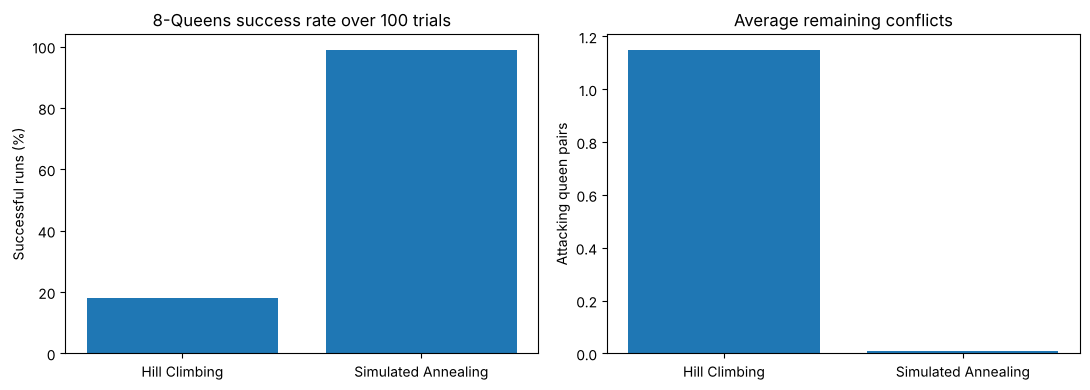

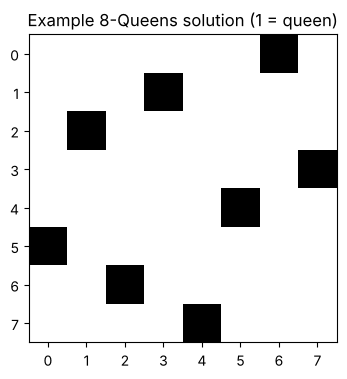

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(local_summary["algorithm"], local_summary["success_rate"])
axes[0].set_title(f"8-Queens success rate over {TRIALS} trials")
axes[0].set_ylabel("Successful runs (%)")
axes[1].bar(local_summary["algorithm"], local_summary["average_final_conflicts"])
axes[1].set_title("Average remaining conflicts")
axes[1].set_ylabel("Attacking queen pairs")
plt.tight_layout()
plt.show()

# show one solution found by simulated annealing
solved_trials = local_results[(local_results["algorithm"] == "Simulated Annealing") & local_results["solved"]]
example = simulated_annealing(n=N_QUEENS, seed=RANDOM_SEED + int(solved_trials.index[0] // 2))
board = np.zeros((N_QUEENS, N_QUEENS))
for col, row in enumerate(example["state"]):
    board[row, col] = 1
plt.figure(figsize=(4, 4))
plt.imshow(board, cmap="Greys", vmin=0, vmax=1)
plt.xticks(range(N_QUEENS)); plt.yticks(range(N_QUEENS))
plt.title("Example 8-Queens solution (1 = queen)")
plt.show()

## 8. Constraint Satisfaction Problem: map colouring

Each region is a variable, the colours are its domain and neighbouring regions must get different colours. We compare:

1. **Backtracking:** assigns variables in a fixed order and backtracks when a constraint is violated.
2. **MRV + Forward Checking:** picks the variable with the fewest remaining legal colours (MRV), and after each assignment removes that colour from the domains of its neighbours. If a neighbour has no colours left it backtracks immediately.

Both are run on the Australia map first, and then on random maps with 40 regions, because Australia is too small to show a difference. The solvers stop after 100000 assignments.

In [10]:
australia_neighbors = {
    "WA": {"NT", "SA"},
    "NT": {"WA", "SA", "Q"},
    "SA": {"WA", "NT", "Q", "NSW", "V"},
    "Q": {"NT", "SA", "NSW"},
    "NSW": {"Q", "SA", "V"},
    "V": {"SA", "NSW"},
    "T": set(),
}
COLORS = ["Red", "Green", "Blue"]
LIMIT = 100000

class LimitReached(Exception):
    pass

def basic_backtracking(neighbors_map, colors):
    variables = list(neighbors_map)
    assignment = {}
    stats = {"assignments": 0, "backtracks": 0}

    def backtrack():
        if len(assignment) == len(variables):
            return True
        variable = next(v for v in variables if v not in assignment)
        for color in colors:
            stats["assignments"] += 1
            if stats["assignments"] > LIMIT:
                raise LimitReached
            if all(assignment.get(nb) != color for nb in neighbors_map[variable]):
                assignment[variable] = color
                if backtrack():
                    return True
                del assignment[variable]
        stats["backtracks"] += 1
        return False

    try:
        solved = backtrack()
    except LimitReached:
        solved = False
    return (assignment.copy() if solved else None), stats

def mrv_forward_checking(neighbors_map, colors):
    variables = list(neighbors_map)
    assignment = {}
    domains = {v: list(colors) for v in variables}
    stats = {"assignments": 0, "backtracks": 0}

    def backtrack():
        if len(assignment) == len(variables):
            return True
        unassigned = [v for v in variables if v not in assignment]
        variable = min(unassigned, key=lambda v: (len(domains[v]), -len([n for n in neighbors_map[v] if n not in assignment])))
        for color in domains[variable][:]:
            stats["assignments"] += 1
            if stats["assignments"] > LIMIT:
                raise LimitReached
            assignment[variable] = color
            removed = []
            failed = False
            for nb in neighbors_map[variable]:
                if nb not in assignment and color in domains[nb]:
                    domains[nb].remove(color)
                    removed.append(nb)
                    if not domains[nb]:
                        failed = True
                        break
            if not failed and backtrack():
                return True
            for nb in removed:
                domains[nb].append(color)
            del assignment[variable]
        stats["backtracks"] += 1
        return False

    try:
        solved = backtrack()
    except LimitReached:
        solved = False
    return (assignment.copy() if solved else None), stats

def valid(solution, neighbors_map):
    return all(solution[a] != solution[b] for a in neighbors_map for b in neighbors_map[a])

csp_rows = []
for name, solver in [("Backtracking", basic_backtracking), ("MRV + Forward Checking", mrv_forward_checking)]:
    t0 = time.perf_counter()
    solution, stats = solver(australia_neighbors, COLORS)
    elapsed = (time.perf_counter() - t0) * 1000
    print(name, "solution:", solution)
    csp_rows.append({"algorithm": name, "solution_found": solution is not None and valid(solution, australia_neighbors),
                     "assignments_tried": stats["assignments"], "backtracks": stats["backtracks"], "time_ms": elapsed})
print()
print(pd.DataFrame(csp_rows).round(4).to_string(index=False))

Backtracking solution: {'WA': 'Red', 'NT': 'Green', 'SA': 'Blue', 'Q': 'Red', 'NSW': 'Green', 'V': 'Red', 'T': 'Red'}
MRV + Forward Checking solution: {'SA': 'Red', 'NT': 'Green', 'Q': 'Blue', 'NSW': 'Green', 'WA': 'Blue', 'V': 'Blue', 'T': 'Red'}

             algorithm  solution_found  assignments_tried  backtracks  time_ms
          Backtracking            True                 11           0   0.0279
MRV + Forward Checking            True                  7           0   0.0410


                        solved_percent  average_assignments  \
algorithm                                                     
Backtracking                      10.0              93219.4   
MRV + Forward Checking           100.0                 47.1   

                        median_assignments  average_backtracks  \
algorithm                                                        
Backtracking                      100001.0             31054.8   
MRV + Forward Checking                43.0                 6.0   

                        average_time_ms  
algorithm                                
Backtracking                       64.2  
MRV + Forward Checking              0.4  


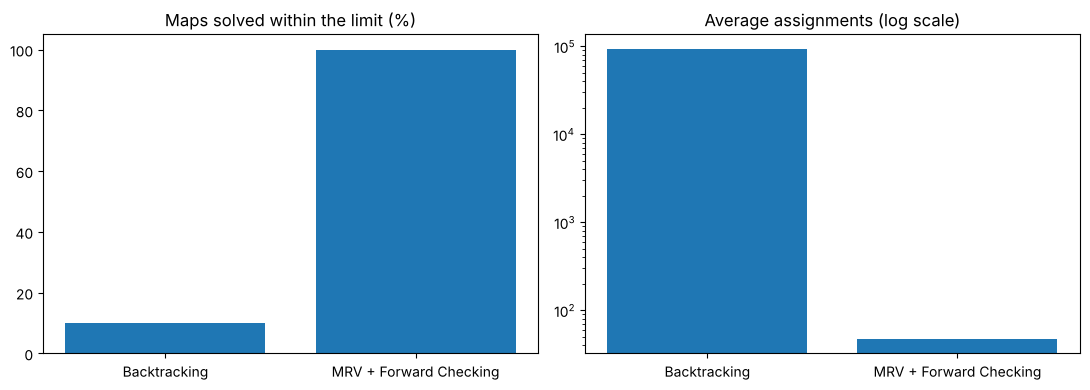

In [11]:
def random_map(n, seed):
    # plant a 3-colouring first so the map always has a solution, then add random edges
    rng = random.Random(seed)
    planted = {i: rng.randrange(3) for i in range(n)}
    nbs = {i: set() for i in range(n)}
    pairs = [(a, b) for a in range(n) for b in range(a + 1, n) if planted[a] != planted[b]]
    for a, b in rng.sample(pairs, int(2.2 * n)):
        nbs[a].add(b)
        nbs[b].add(a)
    return nbs

rows = []
for seed in range(20):
    nbs = random_map(40, seed)
    for name, solver in [("Backtracking", basic_backtracking), ("MRV + Forward Checking", mrv_forward_checking)]:
        t0 = time.perf_counter()
        solution, stats = solver(nbs, [0, 1, 2])
        elapsed = (time.perf_counter() - t0) * 1000
        rows.append({"algorithm": name, "solved": solution is not None and valid(solution, nbs),
                     "assignments": stats["assignments"], "backtracks": stats["backtracks"], "time_ms": elapsed})

csp_many = pd.DataFrame(rows)
csp_summary = csp_many.groupby("algorithm").agg(
    solved_percent=("solved", "mean"),
    average_assignments=("assignments", "mean"),
    median_assignments=("assignments", "median"),
    average_backtracks=("backtracks", "mean"),
    average_time_ms=("time_ms", "mean"))
csp_summary["solved_percent"] *= 100
print(csp_summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(csp_summary.index, csp_summary["solved_percent"])
axes[0].set_title("Maps solved within the limit (%)")
axes[1].bar(csp_summary.index, csp_summary["average_assignments"])
axes[1].set_yscale("log")
axes[1].set_title("Average assignments (log scale)")
plt.tight_layout()
plt.show()

## 9. Overall observations

* BFS found the path with the fewest moves (38) but its cost was 78, because it does not look at the rough cells. UCS and A* both found the cheapest path (cost 56). Over 30 mazes they were optimal every time and BFS, DFS and Greedy never were.
* A* expanded fewer nodes than UCS (206 against 282 on average), so the heuristic helps. It was not much faster in milliseconds because every node also costs a heuristic call and a heap push, and the maze is small.
* Greedy expanded the fewest nodes (54 on average) but its paths cost about 58% more than the best. DFS was cheap but gave the worst paths (average cost 137).
* Hill Climbing solved 8-Queens in only 18% of the runs because it stops at local minima. Simulated Annealing solved 99% of them, but needed far more steps (about 1223 on average) and about 7 times the time.
* Backtracking solved only 10% of the random 40-region maps within 100000 assignments, while MRV + Forward Checking solved all 20 with about 47 assignments on average. On the Australia map the difference is small (11 against 7 assignments), so the small example hides it.
* The timings are from Python on one machine, so the ratios are more reliable than the exact milliseconds.

In [12]:
# sanity checks
ucs_cost = next(r["path_cost"] for r in graph_results if r["algorithm"] == "UCS")
astar_cost = next(r["path_cost"] for r in graph_results if r["algorithm"] == "A*")
greedy_cost = next(r["path_cost"] for r in graph_results if r["algorithm"] == "Greedy")
assert astar_cost == ucs_cost, "A* and UCS should have the same cost"
assert greedy_cost >= ucs_cost
assert all(r["solution_found"] for r in csp_rows)
assert queen_conflicts([0, 4, 7, 5, 2, 6, 1, 3]) == 0
print("All validation checks passed.")

All validation checks passed.


## 10. Conclusion

Different search strategies were evaluated on suitable benchmarks:

* **Uninformed and informed search:** BFS only minimises the number of moves, so UCS or A* is needed when costs differ. A* with the Manhattan heuristic gave the same optimal cost as UCS with fewer expanded nodes. Greedy is fast but not optimal.
* **Local search:** Simulated Annealing fixed most of the local minima problem of Hill Climbing (18% to 99% success on 8-Queens), but it gives no guarantee of finding a solution.
* **CSP:** Choosing the most constrained variable and checking neighbours early (MRV + Forward Checking) solved the maps that plain backtracking could not.

No single algorithm fits every task. A* suits path finding with a good heuristic, local search suits problems where only the final state matters, and CSP methods suit problems with hard constraints.

Notes: the search only optimises the cost it is given, so a real route planner must also check what its cost function ignores (safety, fairness). The benchmarks are small random instances, so a future step would be to try IDA*, arc consistency (AC-3) and larger problems.